# Data Understanding

In [26]:
import os
from zipfile import ZipFile
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models

In [27]:
import random
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)
sns.set_style('whitegrid')

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("abdallahalidev/plantvillage-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
Path to dataset files: /kaggle/input/plantvillage-dataset


In [4]:
os.listdir(path)

['plantvillage dataset']

In [5]:
os.listdir(os.path.join(path, 'plantvillage dataset'))

['segmented', 'grayscale', 'color']

In [6]:
print('Segmented:')
print(os.listdir(os.path.join(path, 'plantvillage dataset', 'segmented'))[:5])
print(len(os.listdir(os.path.join(path, 'plantvillage dataset', 'segmented'))))

print('\nGrayscale:')
print(os.listdir(os.path.join(path, 'plantvillage dataset', 'grayscale'))[:5])
print(len(os.listdir(os.path.join(path, 'plantvillage dataset', 'grayscale'))))

print('\nColor:')
print(os.listdir(os.path.join(path, 'plantvillage dataset', 'color'))[:5])
print(len(os.listdir(os.path.join(path, 'plantvillage dataset', 'color'))))

Segmented:
['Tomato___Late_blight', 'Tomato___healthy', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Soybean___healthy']
38

Grayscale:
['Tomato___Late_blight', 'Tomato___healthy', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Soybean___healthy']
38

Color:
['Tomato___Late_blight', 'Tomato___healthy', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Soybean___healthy']
38


# Data Preparation

In [7]:
base_dir = os.path.join(path, 'plantvillage dataset', 'color')

In [8]:
img_path = os.path.join(base_dir, 'Tomato___healthy', '4a1e2b71-992a-4a64-a599-b49b8fa75378___RS_HL 0627.JPG')
img = mpimg.imread(img_path)

(256, 256, 3)


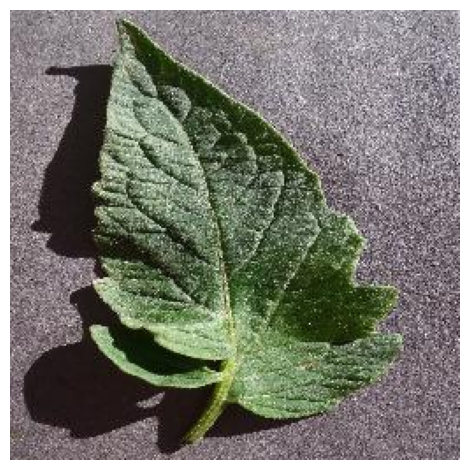

In [9]:
print(img.shape)
plt.imshow(img)
plt.axis('off')
plt.tight_layout()

In [10]:
# img param
img_size = 224
batch_size = 32

Train Test Split

In [11]:
data_gen = ImageDataGenerator(rescale=1./255, validation_split=0.2)

In [12]:
train_generator = data_gen.flow_from_directory(
    base_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    subset='training',
    class_mode='categorical'
)

Found 43456 images belonging to 38 classes.


In [13]:
validation_generator = data_gen.flow_from_directory(
    base_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    subset='validation',
    class_mode='categorical'
)

Found 10849 images belonging to 38 classes.


# Modeling

### Build CNN

In [14]:
model = models.Sequential()

model.add(layers.Conv2D(32, (3,3), activation='relu', input_shape=(img_size, img_size, 3)))
model.add(layers.MaxPooling2D(2,2))

model.add(layers.Conv2D(64, (3,3), activation='relu'))
model.add(layers.MaxPooling2D(2,2))

model.add(layers.Flatten())
model.add(layers.Dense(256, activation='relu'))
model.add(layers.Dense(train_generator.num_classes, activation='softmax'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [15]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 186624)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    47,776,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │         9,766 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 47,805,158 (182.36 MB)

 Trainable params: 47,805,158 (182.36 MB)

 Non-trainable params: 0 (0.00 B)

### Compiling and Train the Model

In [16]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [19]:
history = model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // batch_size,
    epochs=5,
    validation_data=validation_generator,
    validation_steps=validation_generator.samples // batch_size
)

Epoch 1/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 372s 268ms/step - accuracy: 0.7401 - loss: 0.9137 - val_accuracy: 0.8696 - val_loss: 0.4202
Epoch 2/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 153s 113ms/step - accuracy: 0.9080 - loss: 0.2905 - val_accuracy: 0.8786 - val_loss: 0.4011
Epoch 3/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 141s 104ms/step - accuracy: 0.9589 - loss: 0.1284 - val_accuracy: 0.8758 - val_loss: 0.4580
Epoch 4/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 160s 118ms/step - accuracy: 0.9709 - loss: 0.0899 - val_accuracy: 0.8362 - val_loss: 0.7237
Epoch 5/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 137s 101ms/step - accuracy: 0.9756 - loss: 0.0773 - val_accuracy: 0.8827 - val_loss: 0.5104


# Model Evaluation

In [20]:
val_loss, val_accuracy = model.evaluate(validation_generator, steps=validation_generator.samples // batch_size)
print(f'Validation Accuracy: {val_accuracy*100:.2f}%')

339/339 ━━━━━━━━━━━━━━━━━━━━ 26s 76ms/step - accuracy: 0.8827 - loss: 0.5104
Validation Accuracy: 88.27%


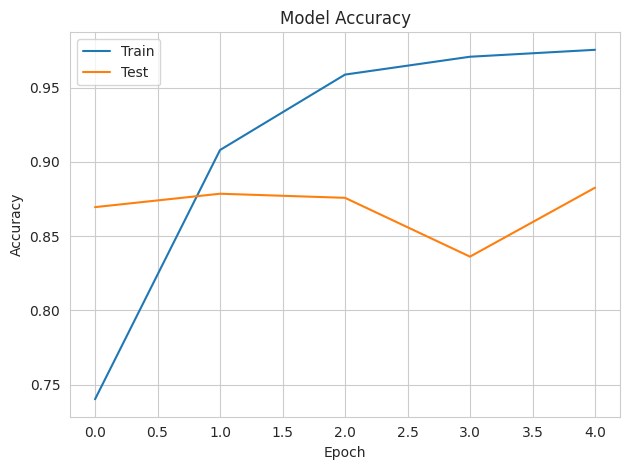

In [28]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(('Train', 'Test'), loc='upper left')
plt.tight_layout()

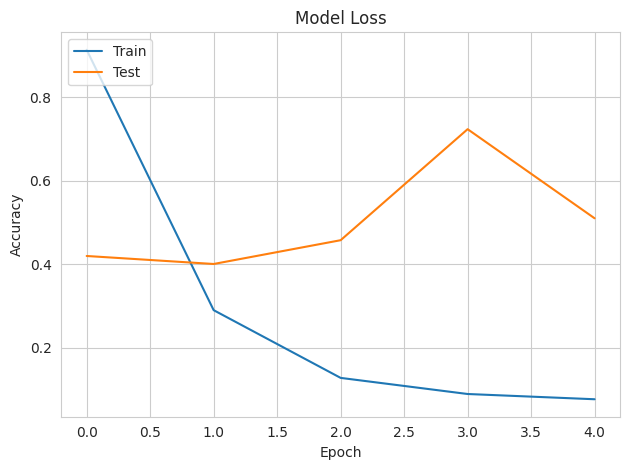

In [29]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(('Train', 'Test'), loc='upper left')
plt.tight_layout()

In [25]:
model.save('plant_disesase_classifier.keras')

# Deployment

### Predictive System

In [ ]:
def load_n_preprocess_img(img_path, target_size=(224,224)):
    # Load img
    img = Image.open(img_path)
    # Resize img
    img = img.resize(target_size)
    # Convert img to np.array
    img_arr = 